<a href="https://colab.research.google.com/github/heri-espino/LDS1071-Machine-Learning/blob/main/notebooks/13_Text-clustering_TFIDF-vs-CountVectorizer_R3_entregable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 6 · Agrupamiento de documentos
### Comparación de TF-IDF y CountVectorizer

**Objetivo:** comprobar cómo cambia K-means al representar los mismos textos mediante TF-IDF o frecuencias de palabras (BoW).

Usaremos **20 Newsgroups**, cuatro categorías y los parámetros de la *Sesión 19* (diapositivas 40–48). Las categorías reales se utilizarán **solo para evaluar**, no para entrenar los clusters.

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="tab10")

from IPython.display import display, Markdown
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import TruncatedSVD

pd.set_option("display.max_colwidth", 120)

In [46]:
categorias = [
    "sci.space",
    "rec.sport.baseball",
    "comp.graphics",
    "talk.politics.mideast",
]

datos = fetch_20newsgroups(
    subset="train",
    categories=categorias,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=42,
)

documentos = datos.data
print(f"Documentos: {len(documentos)}")
print("Ejemplo de texto:\n", documentos[11][:500])

Documentos: 2338
Ejemplo de texto:
 




I'm not sure I understand this question. When the IF rule is invoked,
the batter is automatically out. This relieves the runners from being
forced to advance to the next base if the ball is not caught. Other
than that, isn't it just the same as any situation in which a runner on
a base is not forced to the next base on a dropped fly ball? That is,
if the ball is caught he can tag up and run (or decide to stay), and
if the ball is dropped he can have left the base at any time.



In [47]:
parametros = dict(
    stop_words="english",
    min_df=5,
    max_df=0.8,
    max_features=5000,
)

vectorizador_tfidf = TfidfVectorizer(**parametros, norm="l2")
X_tfidf = vectorizador_tfidf.fit_transform(documentos)

vectorizador_count = CountVectorizer(**parametros)
X_count_original = vectorizador_count.fit_transform(documentos)
X_count = normalize(X_count_original, norm="l2")

print("TF-IDF:", X_tfidf.shape)
print("CountVectorizer:", X_count.shape)
print("Mismo vocabulario:", np.array_equal(
    vectorizador_tfidf.get_feature_names_out(),
    vectorizador_count.get_feature_names_out()
))

TF-IDF: (2338, 5000)
CountVectorizer: (2338, 5000)
Mismo vocabulario: True


### Comprobación de la norma L2

Para cada documento no vacío, la norma debe ser 1:

$$
\hat{x}=\frac{x}{\|x\|_2},\qquad \|\hat{x}\|_2=1.
$$

Los textos vacíos después del filtrado conservan un vector cero.

Count + L2: 2254 no nulos; norma≈1: True
TF-IDF: 2254 no nulos; norma≈1: True


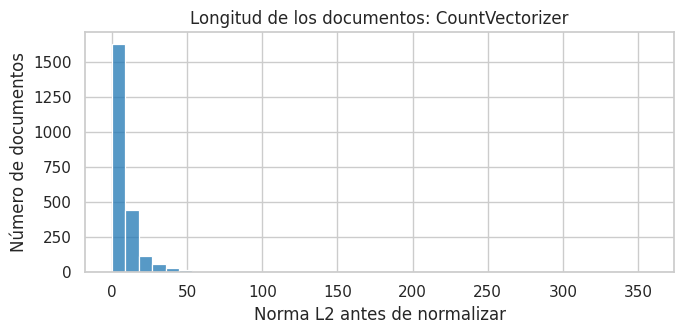

In [48]:
def normas_filas(X):
    return np.sqrt(X.multiply(X).sum(axis=1)).A1

normas_antes = normas_filas(X_count_original)
normas_count = normas_filas(X_count)
normas_tfidf = normas_filas(X_tfidf)

for nombre, valores in [("Count + L2", normas_count), ("TF-IDF", normas_tfidf)]:
    no_nulos = valores > 0
    print(f"{nombre}: {no_nulos.sum()} no nulos; ", end="")
    print("norma≈1:", np.allclose(valores[no_nulos], 1.0))

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(normas_antes, bins=40, ax=ax)
ax.set(xlabel="Norma L2 antes de normalizar", ylabel="Número de documentos",
       title="Longitud de los documentos: CountVectorizer")
fig.tight_layout()
plt.show()

### Interpretación de la normalización

Los dos métodos producen **2,254 vectores no nulos** de **2,338 documentos**. La normalización reduce el efecto de la longitud.

## K-means para K = 2, ..., 8

Para cada representación calculamos:

- **Inercia:** dispersión dentro de los clusters; menor suele ser mejor, pero siempre baja al aumentar K.
- **Silueta:** cohesión y separación; mayor suele ser mejor.


In [49]:
valores_k = range(2, 9)


def evaluar_kmeans(X, representacion):
    modelos = {}
    filas = []

    for k in valores_k:
        modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
        etiquetas = modelo.fit_predict(X)
        silueta = silhouette_score(
            X, etiquetas, metric="euclidean",
            sample_size=min(1000, X.shape[0]), random_state=42,
        )
        modelos[k] = modelo
        filas.append({
            "Representación": representacion,
            "K": k,
            "Inercia": modelo.inertia_,
            "Silueta": silueta,
        })

    return pd.DataFrame(filas), modelos


resultados_tfidf, modelos_tfidf = evaluar_kmeans(X_tfidf, "TF-IDF")
resultados_count, modelos_count = evaluar_kmeans(X_count, "Count + L2")
resultados = pd.concat([resultados_tfidf, resultados_count], ignore_index=True)

display(resultados.round(4))

,Representación,K,Inercia,Silueta
0,TF-IDF,2,2207.3318,0.0161
1,TF-IDF,3,2196.6926,0.0136
2,TF-IDF,4,2185.4386,0.0158
3,TF-IDF,5,2176.2641,0.0121
4,TF-IDF,6,2168.0679,0.0108
5,TF-IDF,7,2163.7142,0.0101
6,TF-IDF,8,2159.4423,0.0065
7,Count + L2,2,2184.7964,0.0138
8,Count + L2,3,2168.8650,0.0139
9,Count + L2,4,2153.9914,0.0160


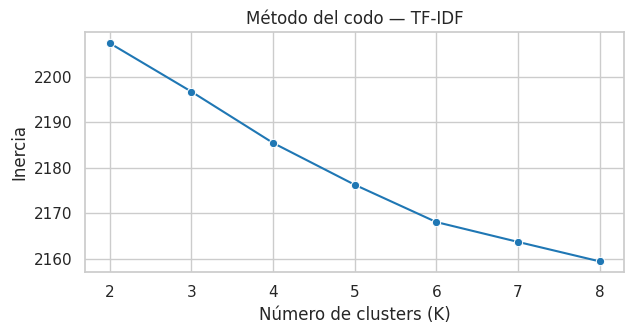

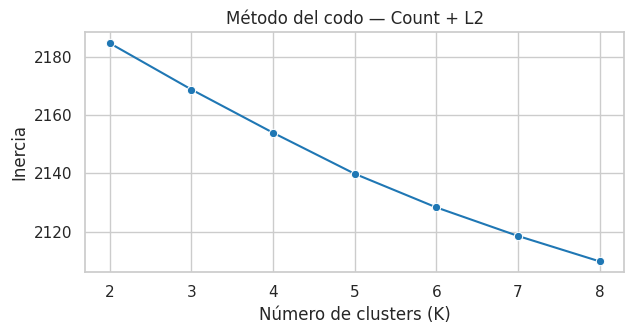

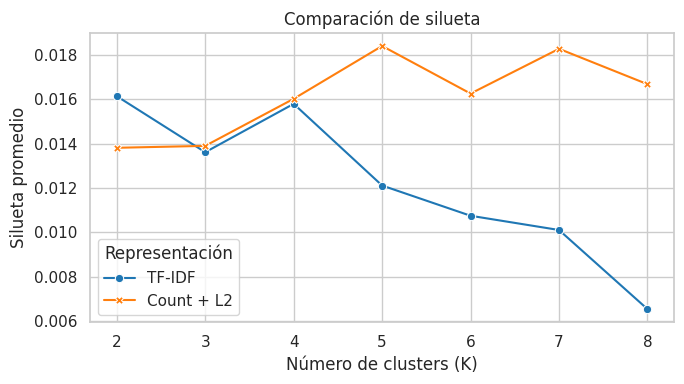

In [50]:
for nombre, tabla in [("TF-IDF", resultados_tfidf), ("Count + L2", resultados_count)]:
    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    sns.lineplot(data=tabla, x="K", y="Inercia", marker="o", ax=ax)
    ax.set(xticks=list(valores_k), xlabel="Número de clusters (K)",
           ylabel="Inercia", title=f"Método del codo — {nombre}")
    fig.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=resultados, x="K", y="Silueta",
             hue="Representación", style="Representación",
             markers=True, dashes=False, ax=ax)
ax.set(xticks=list(valores_k), xlabel="Número de clusters (K)",
       ylabel="Silueta promedio", title="Comparación de silueta")
fig.tight_layout()
plt.show()

### Interpretación de la selección de K

La inercia cae al aumentar K, sin un codo inequívoco. **TF-IDF alcanza su mayor silueta en K=2 (0.0161)**, mientras que **Count + L2 lo hace en K=5 (0.0184)**, casi igual que K=7 (0.0183).

## 5. Elegir K y comparar los resultados

Usaremos **K = 5** para ambas representaciones porque maximiza la silueta de **Count + L2** entre los valores evaluados.


In [51]:
k_elegido = 5

filas_resumen = []
for nombre, tabla in [("TF-IDF", resultados_tfidf), ("Count + L2", resultados_count)]:
    mejor = tabla.loc[tabla["Silueta"].idxmax()]
    elegida = tabla.loc[tabla["K"] == k_elegido].iloc[0]
    filas_resumen.append({
        "Representación": nombre,
        "K elegido": k_elegido,
        "Silueta (K elegido)": elegida["Silueta"],
        "K con mejor silueta": int(mejor["K"]),
        "Mejor silueta": mejor["Silueta"],
    })

resumen = pd.DataFrame(filas_resumen)
display(resumen.round(4))

modelos_elegidos = {
    "TF-IDF": modelos_tfidf[k_elegido],
    "Count + L2": modelos_count[k_elegido],
}

,Representación,K elegido,Silueta (K elegido),K con mejor silueta,Mejor silueta
0,TF-IDF,5,0.0121,2,0.0161
1,Count + L2,5,0.0184,5,0.0184


## Interpretar los clusters

Extraemos las **10 palabras con mayor peso en cada centroide**.

In [52]:
def palabras_principales(modelo, vectorizador, cantidad=10):
    terminos = vectorizador.get_feature_names_out()
    filas = []
    for i, centroide in enumerate(modelo.cluster_centers_):
        indices = np.argsort(centroide)[-cantidad:][::-1]
        filas.append({
            "Cluster": i,
            "10 palabras principales": ", ".join(terminos[indices]),
        })
    return pd.DataFrame(filas)


palabras_tfidf = palabras_principales(modelos_elegidos["TF-IDF"], vectorizador_tfidf)
palabras_count = palabras_principales(modelos_elegidos["Count + L2"], vectorizador_count)

print("TF-IDF")
display(palabras_tfidf)
print("CountVectorizer + L2")
display(palabras_count)

TF-IDF


,Cluster,10 palabras principales
0,0,"space, just, like, think, don, nasa, time, people, know, does"
1,1,"year, team, game, games, runs, hit, good, think, pitching, braves"
2,2,"armenian, armenians, turkish, people, armenia, turks, turkey, greek, genocide, said"
3,3,"israel, israeli, jews, arab, arabs, adam, israelis, jewish, peace, people"
4,4,"thanks, graphics, files, image, program, know, file, does, looking, hi"


CountVectorizer + L2


,Cluster,10 palabras principales
0,0,"just, think, don, year, like, know, good, team, game, people"
1,1,"thanks, does, know, like, graphics, use, edu, time, program, need"
2,2,"space, nasa, like, earth, launch, shuttle, station, know, think, just"
3,3,"armenian, armenians, turkish, people, armenia, turkey, turks, said, genocide, government"
4,4,"israel, israeli, jews, arab, arabs, people, jewish, peace, israelis, just"


### Interpretación de las palabras

Para TF-IDF, los clusters **1** (*team, game, pitching*) y **4** (*graphics, files, image*) representan béisbol y gráficos. Los clusters **2** y **3** es politica, hablan mucho de noticias armenio-turcas e israelí-árabes. El cluster **0** mezcla *space* y *nasa* con vocabulario general.

Con Count + L2, el cluster **2** se relaciona con espacio; los clusters **3** y **4**, con los mismos dos subtemas políticos. Los clusters **0** y **1** contienen numerosos términos genéricos (*just, think, know, thanks*) y son menos definidos.


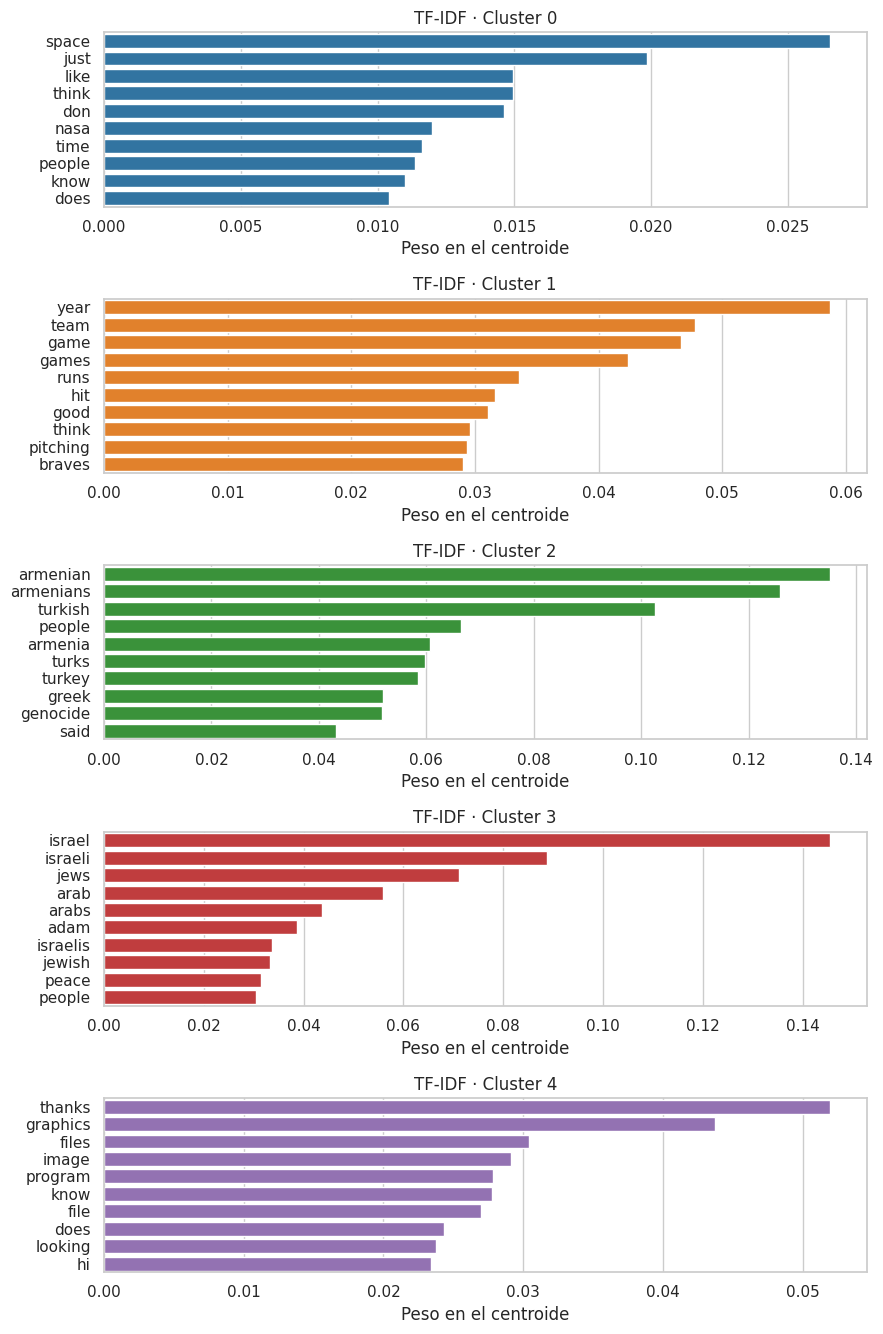

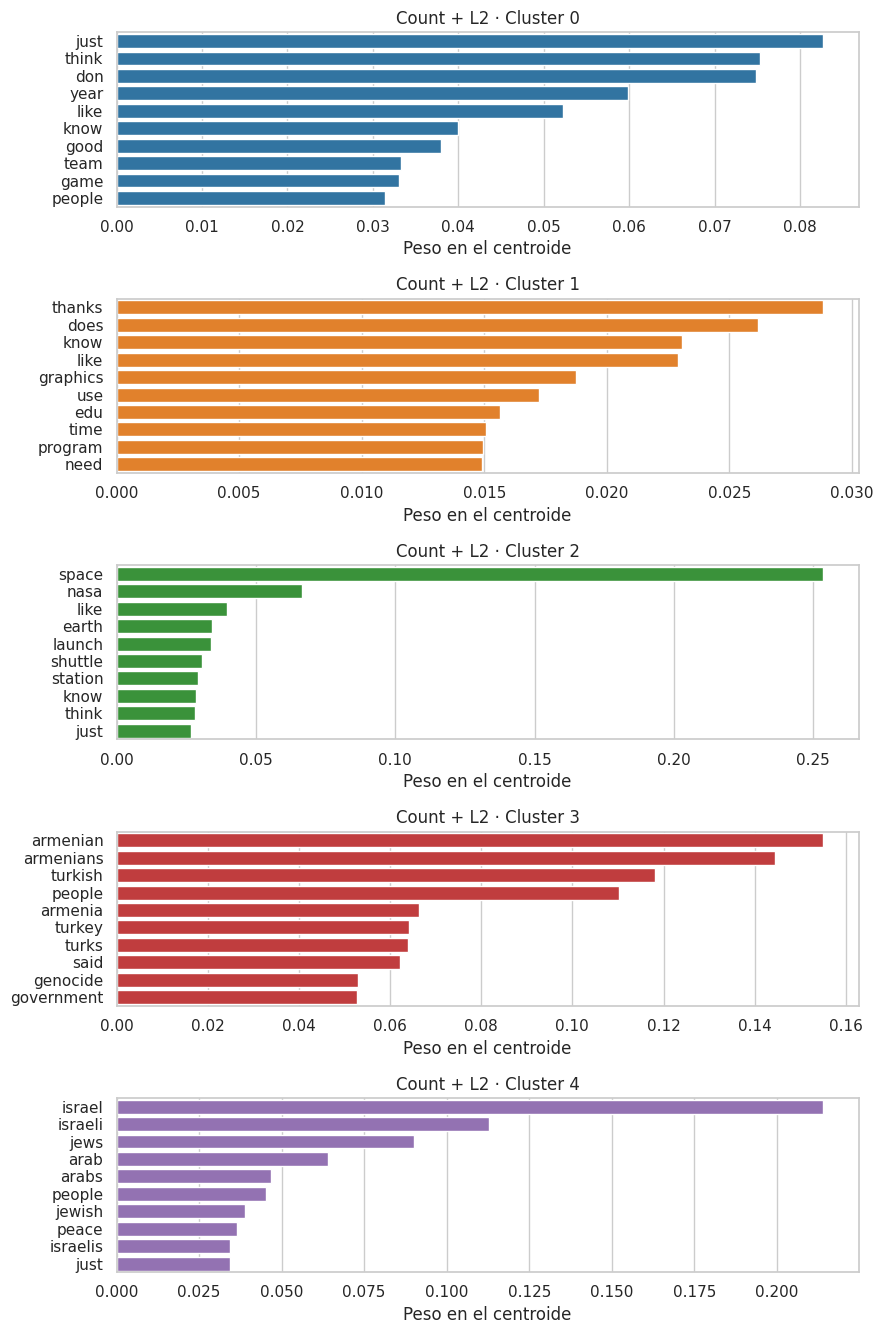

In [53]:
for nombre, vectorizador in [("TF-IDF", vectorizador_tfidf),
                              ("Count + L2", vectorizador_count)]:
    modelo = modelos_elegidos[nombre]
    terminos = vectorizador.get_feature_names_out()
    fig, ejes = plt.subplots(k_elegido, 1, figsize=(9, 2.7 * k_elegido))
    for i, eje in enumerate(np.atleast_1d(ejes)):
        centroide = modelo.cluster_centers_[i]
        indices = np.argsort(centroide)[-10:][::-1]
        sns.barplot(x=centroide[indices], y=terminos[indices],
                    color=sns.color_palette("tab10")[i], ax=eje)
        eje.set(title=f"{nombre} · Cluster {i}", xlabel="Peso en el centroide", ylabel="")
    fig.tight_layout()
    plt.show()

## Comparación con las categorías reales

Las categorías no se utilizaron en el entrenamiento. Ahora las recuperamos **solo para analizar** qué temas aparecen en cada cluster.

In [54]:
etiquetas_reales = [datos.target_names[i] for i in datos.target]

tablas = {}
for nombre, modelo in modelos_elegidos.items():
    tabla = pd.crosstab(
        pd.Series(modelo.labels_, name="Cluster"),
        pd.Series(etiquetas_reales, name="Categoría real"),
    )
    tablas[nombre] = tabla
    print(f"{nombre} — cantidad de documentos por categoría:")
    display(tabla)

TF-IDF — cantidad de documentos por categoría:


Categoría real,comp.graphics,rec.sport.baseball,sci.space,talk.politics.mideast
Cluster,,,,
0,160,255,559,256
1,0,323,2,0
2,0,0,0,117
3,0,0,0,190
4,424,19,32,1


Count + L2 — cantidad de documentos por categoría:


Categoría real,comp.graphics,rec.sport.baseball,sci.space,talk.politics.mideast
Cluster,,,,
0,49,337,107,73
1,529,260,306,202
2,6,0,180,0
3,0,0,0,119
4,0,0,0,170


### Categorías reales

La pureza resultante es **69.0% (TF-IDF)** y **57.1% (Count + L2)**. En TF-IDF, el cluster 1 reúne **323/325** textos de béisbol y el cluster 4, **424/476** de gráficos, pero el cluster 0 mezcla **1,230** documentos. En Count + L2, su cluster 1 mezcla **1,297** documentos.

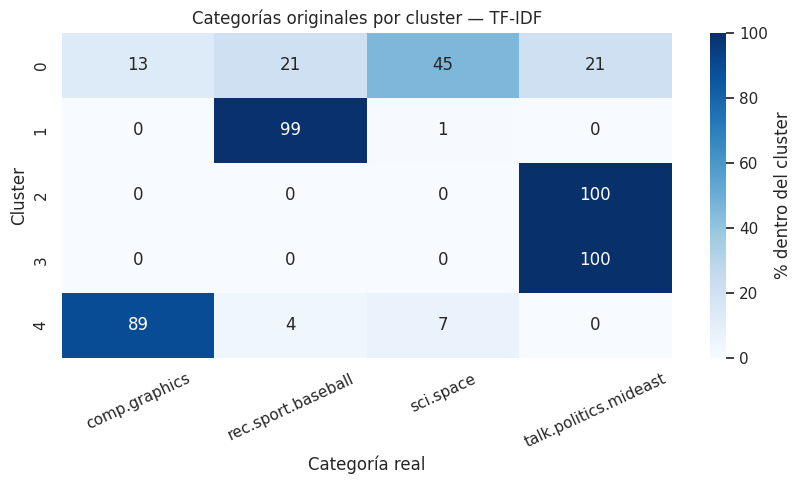

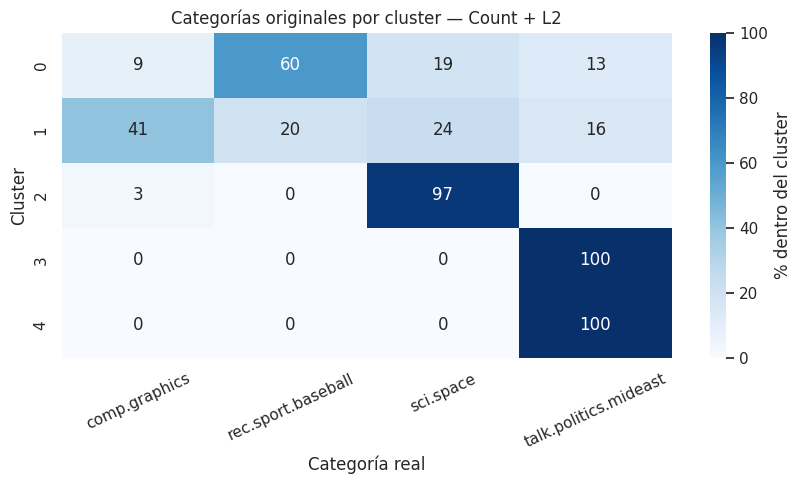

In [55]:
for nombre, tabla in tablas.items():
    porcentajes = tabla.div(tabla.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(8.5, 3.5 + 0.3 * k_elegido))
    sns.heatmap(porcentajes, annot=True, fmt=".0f", cmap="Blues",
                vmin=0, vmax=100, cbar_kws={"label": "% dentro del cluster"}, ax=ax)
    ax.set(title=f"Categorías originales por cluster — {nombre}",
           xlabel="Categoría real", ylabel="Cluster")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    plt.show()

## Visualización en dos dimensiones (SVD)

Reducimos a dos dimensiones **solo para visualizar**. K-means fue entrenado con todos los términos, no con las coordenadas 2D.

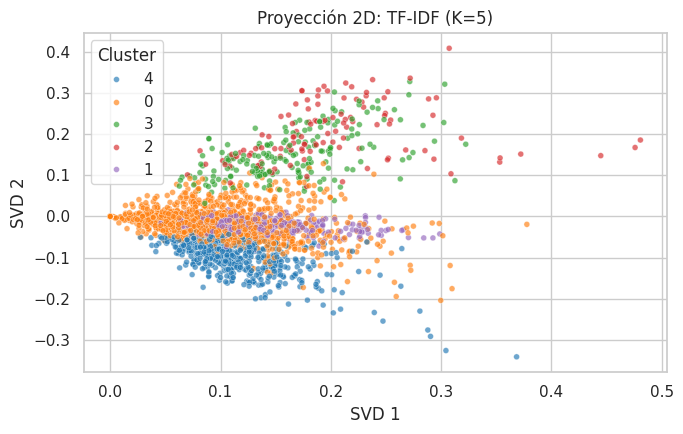

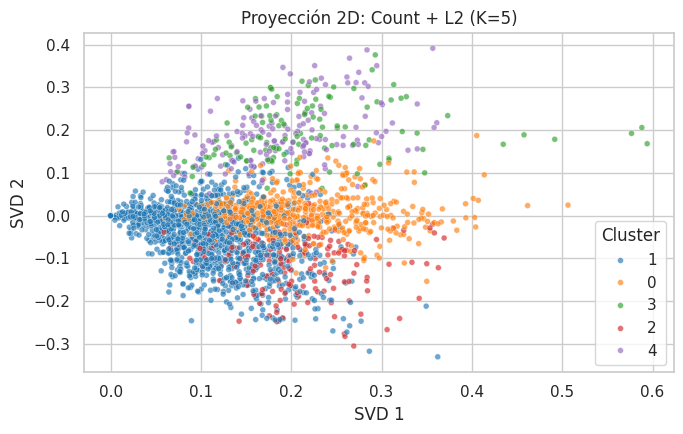

In [56]:
matrices = {"TF-IDF": X_tfidf, "Count + L2": X_count}
for nombre, X in matrices.items():
    coordenadas = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
    datos_2d = pd.DataFrame({
        "SVD 1": coordenadas[:, 0], "SVD 2": coordenadas[:, 1],
        "Cluster": modelos_elegidos[nombre].labels_.astype(str),
    })
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.scatterplot(data=datos_2d, x="SVD 1", y="SVD 2", hue="Cluster",
                    palette="tab10", s=18, alpha=0.65, ax=ax)
    ax.set_title(f"Proyección 2D: {nombre} (K={k_elegido})")
    fig.tight_layout()
    plt.show()

## Preguntas de análisis

In [61]:
# Respuestas basadas en los resultados calculados. Complementar la interpretación personal.
mejor_t = resultados_tfidf.loc[resultados_tfidf["Silueta"].idxmax()]
mejor_c = resultados_count.loc[resultados_count["Silueta"].idxmax()]

# Pureza descriptiva: proporción de documentos pertenecientes a la categoría
# más numerosa dentro de cada cluster (solo para evaluar, no para entrenar).
pureza = {
    nombre: tabla.max(axis=1).sum() / tabla.to_numpy().sum()
    for nombre, tabla in tablas.items()
}

coincidencia = adjusted_rand_score(
    modelos_elegidos["TF-IDF"].labels_, modelos_elegidos["Count + L2"].labels_
)

pal_t = palabras_tfidf.iloc[0]["10 palabras principales"].split(", ")[:5]
pal_c = palabras_count.iloc[0]["10 palabras principales"].split(", ")[:5]

texto = f"""

**1. ¿Cuál es la diferencia entre TF-IDF y CountVectorizer?**
CountVectorizer utiliza frecuencias directas; TF-IDF reduce el peso relativo de términos frecuentes en muchos documentos.

**2. ¿Por qué normalizamos CountVectorizer?**
Para evitar que la magnitud del vector, asociada en parte a la longitud del documento, domine las distancias euclidianas. Cada vector queda con norma L2 igual a 1.

**3. ¿Qué K tuvo la mayor silueta?**
TF-IDF: **K={int(mejor_t['K'])}**, silueta **{mejor_t['Silueta']:.4f}**.
Count + L2: **K={int(mejor_c['K'])}**, silueta **{mejor_c['Silueta']:.4f}**.

**4. ¿Con qué representación son más fáciles de interpretar los clusters?**
Con **TF-IDF** las representaciones son mas faciles de interpretar.
Para TF-IDF, los clusters **1** (*team, game, pitching*) y **4** (*graphics, files, image*) representan béisbol y gráficos. Los clusters **2** y **3** es politica, hablan mucho de noticias armenio-turcas e israelí-árabes. El cluster **0** mezcla *space* y *nasa* con vocabulario general.
Con Count + L2, el cluster **2** se relaciona con espacio; los clusters **3** y **4**, con los mismos dos subtemas políticos. Los clusters **0** y **1** contienen numerosos términos genéricos (*just, think, know, thanks*) y son menos definidos.
Para **K={k_elegido}**, el primer cluster de TF-IDF incluye **{', '.join(pal_t)}**; el primer cluster de Count + L2 incluye **{', '.join(pal_c)}**.

**5. ¿Los clusters coinciden con las categorías originales?**
Si, en especial cuando son temas politicos. Hubo errores principalmente en temas sobre el espacio, porque se combianaba el cluster del espacio con palabras comunes, si aumentaramos el numero de clusters (quiza a 7) podria haber menos errores, pero quiza podria ser menos interpretable, o se esperearia que se obtuvieran dos clusters que son de palabras comunes y uno especializado en el espacio.
Con K={k_elegido}, las purezas son **{pureza['TF-IDF']:.1%}** (TF-IDF) y **{pureza['Count + L2']:.1%}** (Count + L2). Las asignaciones de ambas representaciones tienen un índice Rand ajustado de **{coincidencia:.3f}** (1 indica coincidencia perfecta). Identifica en las tablas cuáles categorías aparecen mezcladas.

**6. ¿Podrían mejorar los embeddings de documentos?**
Sí, depende de como se haga el embedding, pueden captar relaciones entre documentos que usan palabras diferentes.
"""

display(Markdown(texto))



**1. ¿Cuál es la diferencia entre TF-IDF y CountVectorizer?**  
CountVectorizer utiliza frecuencias directas; TF-IDF reduce el peso relativo de términos frecuentes en muchos documentos.

**2. ¿Por qué normalizamos CountVectorizer?**  
Para evitar que la magnitud del vector, asociada en parte a la longitud del documento, domine las distancias euclidianas. Cada vector queda con norma L2 igual a 1.

**3. ¿Qué K tuvo la mayor silueta?**
TF-IDF: **K=2**, silueta **0.0161**.
Count + L2: **K=5**, silueta **0.0184**.

**4. ¿Con qué representación son más fáciles de interpretar los clusters?**
Con **TF-IDF** las representaciones son mas faciles de interpretar.
Para TF-IDF, los clusters **1** (*team, game, pitching*) y **4** (*graphics, files, image*) representan béisbol y gráficos. Los clusters **2** y **3** es politica, hablan mucho de noticias armenio-turcas e israelí-árabes. El cluster **0** mezcla *space* y *nasa* con vocabulario general.
Con Count + L2, el cluster **2** se relaciona con espacio; los clusters **3** y **4**, con los mismos dos subtemas políticos. Los clusters **0** y **1** contienen numerosos términos genéricos (*just, think, know, thanks*) y son menos definidos.
Para **K=5**, el primer cluster de TF-IDF incluye **space, just, like, think, don**; el primer cluster de Count + L2 incluye **just, think, don, year, like**.

**5. ¿Los clusters coinciden con las categorías originales?**
Si, en especial cuando son temas politicos. Hubo errores principalmente en temas sobre el espacio, porque se combianaba el cluster del espacio con palabras comunes, si aumentaramos el numero de clusters (quiza a 7) podria haber menos errores, pero quiza podria ser menos interpretable, o se esperearia que se obtuvieran dos clusters que son de palabras comunes y uno especializado en el espacio. 
Con K=5, las purezas son **69.0%** (TF-IDF) y **57.1%** (Count + L2). Las asignaciones de ambas representaciones tienen un índice Rand ajustado de **0.251** (1 indica coincidencia perfecta). Identifica en las tablas cuáles categorías aparecen mezcladas.

**6. ¿Podrían mejorar los embeddings de documentos?**
Sí, depende de como se haga el embedding, pueden captar relaciones entre documentos que usan palabras diferentes. 


# R3 visualization

## 10. De PCA a la esfera y luego a K-means

1. **PCA:** proyectamos cada documento a $\mathbb{R}^3$ (sin colores de cluster).
2. **Esfera:** normalizamos las coordenadas 3D por su norma L2.
3. **K-means:** entrenamos un **nuevo modelo K=5 sobre la esfera**; después coloreamos los clusters y destacamos sus vecinos.
4. **Original:** opcionalmente, mostramos las asignaciones del K-means anterior (entrenado en 5,000 dimensiones) para comparar.



In [58]:
# Plotly permite rotar y acercar los gráficos con el ratón.
# Si hace falta: %pip install plotly
import plotly.graph_objects as go
from sklearn.decomposition import PCA

max_docs_r3 = 1000
n_vecinos = 15  # Documentos más cercanos a cada centroide

rng = np.random.default_rng(42)
indices_r3 = np.sort(rng.choice(
    len(documentos), size=min(max_docs_r3, len(documentos)), replace=False
))

print(f"Visualizaremos {len(indices_r3)} documentos (la misma muestra en ambos métodos).")

Visualizaremos 1000 documentos (la misma muestra en ambos métodos).


### Preparación

PCA utiliza una muestra fija de 1,000 documentos. Normalizamos **después** de proyectar: $z_i=\operatorname{PCA}(x_i)$ y $u_i=z_i/\|z_i\|_2$. Luego K-means ajusta sus centroides sobre $u_i$. En K-means estándar, los centroides pueden estar **dentro** de la esfera; no es *spherical K-means*.


In [59]:
visualizaciones_r3 = {}
for nombre, X in matrices.items():
    X_muestra = X[indices_r3].toarray().astype(np.float32)

    # 1. Proyectar 5000 dimensiones a R3 con PCA.
    pca = PCA(n_components=3, svd_solver="randomized", random_state=42)
    coords = pca.fit_transform(X_muestra)

    # 2. Normalizar las coordenadas: esfera unitaria.
    esfera = normalize(coords, norm="l2")

    # 3. Entrenar un nuevo K-means en la esfera.
    kmeans_3d = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
    grupos = kmeans_3d.fit_predict(esfera)

    # Los vecinos pertenecen a su cluster y se ordenan por distancia al centroide 3D.
    distancias = kmeans_3d.transform(esfera)
    vecinos = {}
    for k in range(k_elegido):
        miembros = np.flatnonzero(grupos == k)
        vecinos[k] = miembros[np.argsort(distancias[miembros, k])[:n_vecinos]]

    visualizaciones_r3[nombre] = {
        "coords": coords,
        "esfera": esfera,
        "grupos": grupos,
        "centroides": kmeans_3d.cluster_centers_,
        "vecinos": vecinos,
        "grupos_originales": modelos_elegidos[nombre].labels_[indices_r3],
        "varianza": pca.explained_variance_ratio_.sum(),
    }
    normas = np.linalg.norm(esfera, axis=1)
    print(f"{nombre}: varianza explicada = {pca.explained_variance_ratio_.sum():.1%}; "
          f"norma L2=1: {np.isclose(normas[normas > 0], 1).all()}")

TF-IDF: varianza explicada = 2.5%; norma L2=1: True
Count + L2: varianza explicada = 3.4%; norma L2=1: True


In [60]:
def mostrar_r3(nombre):
    datos_r3 = visualizaciones_r3[nombre]
    coords, esfera = datos_r3["coords"], datos_r3["esfera"]
    grupos, vecinos = datos_r3["grupos"], datos_r3["vecinos"]
    originales = datos_r3["grupos_originales"]
    centroides = datos_r3["centroides"]
    colores = sns.color_palette("tab10", n_colors=k_elegido).as_hex()

    phi = np.linspace(0, 2 * np.pi, 38)
    theta = np.linspace(0, np.pi, 22)
    sx = np.outer(np.cos(phi), np.sin(theta))
    sy = np.outer(np.sin(phi), np.sin(theta))
    sz = np.outer(np.ones_like(phi), np.cos(theta))

    fig = go.Figure()
    vistas = {}

    def puntos(X, ids, titulo, color, tamano=3, opacidad=0.65, leyenda=False):
        fig.add_trace(go.Scatter3d(
            x=X[ids, 0], y=X[ids, 1], z=X[ids, 2],
            customdata=indices_r3[ids],
            hovertemplate="Documento %{customdata}<extra>%{fullData.name}</extra>",
            mode="markers",
            marker=dict(color=color, size=tamano, opacity=opacidad),
            name=titulo, showlegend=leyenda, visible=False))
        return len(fig.data) - 1

    def superficie():
        fig.add_trace(go.Surface(
            x=sx, y=sy, z=sz,
            colorscale=[[0, "#bfdbfe"], [1, "#bfdbfe"]],
            opacity=0.09, hoverinfo="skip",
            showscale=False, showlegend=False, visible=False))
        return len(fig.data) - 1

    def marcar_centroides():
        fig.add_trace(go.Scatter3d(
            x=centroides[:, 0], y=centroides[:, 1], z=centroides[:, 2],
            mode="markers+text", name="Centroides en R3",
            marker=dict(size=7, color="#111827", symbol="diamond"),
            text=[f"C{k}" for k in range(k_elegido)],
            textposition="top center", visible=False, showlegend=True))
        return len(fig.data) - 1

    todos = np.arange(len(indices_r3))
    vistas["1. PCA"] = [puntos(coords, todos, "Documentos", "#64748b")]
    vistas["2. Esfera"] = [
        superficie(), puntos(esfera, todos, "Esfera L2", "#64748b")]

    ids = [superficie()]
    for k in range(k_elegido):
        ids_k = np.flatnonzero(grupos == k)
        ids.append(puntos(esfera, ids_k, f"Cluster 3D {k}", colores[k], leyenda=True))
    ids.append(marcar_centroides())
    vistas["3. K-means"] = ids

    ids = [superficie(), puntos(esfera, todos, "Otros", "#cbd5e1", opacidad=0.12)]
    for k in range(k_elegido):
        ids.append(puntos(esfera, vecinos[k], f"Vecinos del cluster {k}",
                          colores[k], tamano=6, opacidad=1, leyenda=True))
    ids.append(marcar_centroides())
    vistas["4. Vecinos"] = ids

    ids = [superficie()]
    for k in range(k_elegido):
        ids_k = np.flatnonzero(originales == k)
        ids.append(puntos(esfera, ids_k, f"Cluster original {k}",
                          colores[k], leyenda=True))
    vistas["5. Original"] = ids

    def escena(esfera_activada):
        estilo = dict(showbackground=False, gridcolor="#e2e8f0")
        if esfera_activada:
            estilo["range"] = [-1.13, 1.13]
        return dict(xaxis=dict(title="PCA 1", **estilo),
                    yaxis=dict(title="PCA 2", **estilo),
                    zaxis=dict(title="PCA 3", **estilo),
                    aspectmode="cube" if esfera_activada else "data")

    botones = []
    for vista, ids in vistas.items():
        botones.append(dict(
            label=vista, method="update",
            args=[{"visible": [j in ids for j in range(len(fig.data))]},
                  {"title": f"{nombre} · {vista} · K={k_elegido}",
                   "scene": escena(vista != "1. PCA")}]))
    for j in vistas["1. PCA"]:
        fig.data[j].visible = True

    fig.update_layout(
        template="plotly_white", title=f"{nombre} · 1. PCA",
        height=650, margin=dict(l=0, r=0, b=0, t=105),
        legend=dict(x=0.01, y=0.98, bgcolor="rgba(255,255,255,0.75)"),
        updatemenus=[dict(type="buttons", direction="right", buttons=botones,
                          x=0.01, y=1.12, xanchor="left", yanchor="top",
                          bgcolor="#f8fafc", showactive=True)],
        scene=escena(False))
    fig.show()
    return fig

fig_tfidf_r3 = mostrar_r3("TF-IDF")
fig_count_r3 = mostrar_r3("Count + L2")